# Split estratificado por fórmula: train / val / test = 80 / 10 / 10

Este notebook realiza **únicamente la partición** del dataset generado por `pre_processing5.ipynb`. Cada fórmula es un grupo indivisible: todos sus polimorfos, cálculos `static` y frames de relajación se asignan al mismo subconjunto.

El pipeline de referencia es: `pre_processing2` construye configuraciones y labels; `pre_processing3` caracteriza trayectorias; `pre_processing4` elimina endpoints coincidentes; `pre_processing5` reduce las trayectorias hexagonales; **este notebook asigna las configuraciones resultantes a train, val y test**.

No se repiten conversiones desde JSON, limpieza física, eliminación de endpoints, thinning, selección por energía/fuerzas ni balanceo por época. Se conservan todos los registros del EXTXYZ de entrada con sus labels y procedencia. El test representa el dataset recibido, que ya fue procesado aguas arriba; no es la trayectoria cruda completa.

## 1. Unidad de partición y significado de la estratificación

La proporción solicitada se aplica al **número de fórmulas únicas**, no al número de frames. Para 80 fórmulas, los tamaños son exactamente **64 train, 8 val y 8 test**. Para otros tamaños se usa el método de restos mayores: se toma la parte entera de `N × [0.8, 0.1, 0.1]` y se distribuyen las plazas restantes por resto descendente, con desempate train → val → test. Se exige que los tres subconjuntos queden no vacíos.

La fórmula se obtiene de la composición reducida de los átomos. Así, etiquetas equivalentes como `Ba1Ge1S3` y `BaGeS3` no pueden terminar en splits distintos; el texto original se conserva como `formula_original` en el índice de auditoría.

**Estratos:** combinación de `polymorph × data_origin` (por ejemplo, `hexagonal / relax_trajectory`). Una fórmula contiene varios estratos, por lo que no es válido aplicar `train_test_split(stratify=formula)` a frames independientes. Se construye una matriz de conteos por fórmula y estrato y se comparan particiones candidatas de grupos completos.

Las longitudes de trayectoria varían: las proporciones de configuraciones y de cada estrato serán aproximadas. Nunca se rompe una fórmula para mejorar esos porcentajes. El informe mostrará el desvío observado en puntos porcentuales.

## 2. Dependencias, rutas y parámetros reproducibles

Se requieren `ase`, `numpy`, `pandas` y `matplotlib`. Ejecutar de arriba abajo desde la raíz del proyecto, `data` o `data/Preprocess notebooks`. `ABS3_PROJECT_DIR` permite indicar otra raíz; `ABS3_SPLIT_SOURCE` y `ABS3_SPLIT_OUTPUT` permiten cambiar entrada y salida.

Se busca primero la salida existente de `pre_processing5` bajo `Preprocess notebooks/outputs`; también se acepta su ruta original bajo `data`. Si existen ambas, debe elegirse explícitamente la fuente para evitar ambigüedad. No hay fallback al JSON crudo.

`SPLIT_SEED=42` y `N_CANDIDATES=10000` definen la búsqueda. `WRITE_OUTPUTS=False` permite una auditoría sin escritura. Por defecto se escriben archivos nuevos; `OVERWRITE_OUTPUTS=False` protege resultados previos.

In [ ]:
import hashlib
import json
import os
import platform
from pathlib import Path

import ase

MPLCONFIGDIR = Path("/tmp/mplconfig-abs3-formula-split")
MPLCONFIGDIR.mkdir(parents=True, exist_ok=True)
os.environ.setdefault("MPLCONFIGDIR", str(MPLCONFIGDIR))
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from ase.io import read, write
from IPython.display import display


def find_project_dir():
    if os.environ.get("ABS3_PROJECT_DIR"):
        return Path(os.environ["ABS3_PROJECT_DIR"]).expanduser().resolve()
    for root in (Path.cwd(), *Path.cwd().parents):
        if (root / "data/stratification_split.ipynb").is_file():
            return root
    raise FileNotFoundError("Defina ABS3_PROJECT_DIR con la raíz del proyecto.")


PROJECT_DIR = find_project_dir()
DATA_DIR = PROJECT_DIR / "data"
if os.environ.get("ABS3_SPLIT_SOURCE"):
    SOURCE_EXTXYZ = Path(os.environ["ABS3_SPLIT_SOURCE"]).expanduser().resolve()
else:
    candidates = [
        DATA_DIR / "Preprocess notebooks/outputs/hexagonal/configurations_hex_stratified.extxyz",
        DATA_DIR / "configurations_hex_stratified.extxyz",
    ]
    available = [path for path in candidates if path.is_file()]
    if len(available) != 1:
        raise FileNotFoundError(
            f"Se esperaba una fuente inequívoca; encontradas: {available}. "
            "Defina ABS3_SPLIT_SOURCE con el EXTXYZ de pre_processing5."
        )
    SOURCE_EXTXYZ = available[0]
OUTPUT_DIR = Path(os.environ.get(
    "ABS3_SPLIT_OUTPUT", str(DATA_DIR / "outputs/hexagonal/outputs/configurations_hex_no_meta_split")
)).expanduser().resolve()
SPLIT_NAMES = ("train", "val", "test")
SPLIT_FRACTIONS = np.array([0.8, 0.1, 0.1])
SPLIT_SEED = 42
N_CANDIDATES = 10_000
WRITE_OUTPUTS = True
OVERWRITE_OUTPUTS = False

assert SOURCE_EXTXYZ.is_file(), SOURCE_EXTXYZ
assert np.isclose(SPLIT_FRACTIONS.sum(), 1)
print("Fuente:", SOURCE_EXTXYZ)
print("Salida:", OUTPUT_DIR)

Fuente: /users/0/cmadridl/projects/dmc_cristelle-madrid-lopez/projects/ABS3-fine-tuning/dev/data/cml/data/Preprocess notebooks/outputs/hexagonal/configurations_hex_stratified.extxyz
Salida: /users/0/cmadridl/projects/dmc_cristelle-madrid-lopez/projects/ABS3-fine-tuning/dev/data/cml/data/configurations_hex_no_meta_split


## 3. Lectura e integridad de la fuente

Cada fila del índice corresponde a una configuración, en el orden del EXTXYZ. Se exige un `config_id` único, procedencia completa y labels finitos. Los grupos se calculan desde las especies de ASE usando composición reducida; se comprueba que una misma etiqueta original no describa composiciones distintas y que cada trayectoria pertenezca a una sola fórmula.

Se auditan energía total (eV), fuerzas (eV/Å), stress (eV/Å³), posiciones y celda. Estas comprobaciones detienen el notebook ante datos incompletos: no eliminan registros ni modifican unidades. Los conteos se deducen del archivo, sin imponer los resultados históricos de otros notebooks.

In [2]:
def sha256_file(path):
    digest = hashlib.sha256()
    with path.open("rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            digest.update(chunk)
    return digest.hexdigest()


source_hash = sha256_file(SOURCE_EXTXYZ)
atoms_all = read(SOURCE_EXTXYZ, index=":", format="extxyz")
assert atoms_all, "La fuente está vacía."
required_info = {"config_id", "source_key", "formula", "polymorph", "data_origin", "frame_index"}
rows = []
for index, atoms in enumerate(atoms_all):
    missing = required_info.difference(atoms.info)
    assert not missing, (index, sorted(missing))
    for field in required_info - {"frame_index"}:
        assert isinstance(atoms.info[field], str) and atoms.info[field].strip(), (index, field)
    assert atoms.info["data_origin"] in {"static", "relax_trajectory"}
    assert len(atoms) > 0
    assert atoms.get_forces().shape == (len(atoms), 3)
    assert atoms.get_stress(voigt=False).shape == (3, 3)
    for values in (atoms.positions, atoms.cell.array, atoms.get_potential_energy(),
                   atoms.get_forces(), atoms.get_stress(voigt=False)):
        assert np.isfinite(values).all(), index
    assert atoms.get_volume() > 0
    rows.append({
        "source_index": index,
        "config_id": atoms.info["config_id"],
        "source_key": atoms.info["source_key"],
        "formula_original": atoms.info["formula"],
        "formula": str(atoms.symbols.formula.reduce()[0].format("hill")),
        "polymorph": atoms.info["polymorph"],
        "data_origin": atoms.info["data_origin"],
        "frame_index": int(atoms.info["frame_index"]),
    })
configuration_index = pd.DataFrame(rows)
assert configuration_index["config_id"].is_unique
assert configuration_index.groupby("formula_original")["formula"].nunique().eq(1).all()
assert configuration_index.groupby("source_key")["formula"].nunique().eq(1).all()
composition = configuration_index.groupby(["polymorph", "data_origin"]).size().rename("configurations")
print("Configuraciones:", len(configuration_index))
print("Fórmulas:", configuration_index["formula"].nunique())
display(composition.to_frame())
display(configuration_index.head())

Configuraciones: 5310
Fórmulas: 80


configurations
polymorph       data_origin                     
dist_perovskite relax_trajectory            1031
                static                        80
hexagonal       relax_trajectory            3053
                static                        80
needle          relax_trajectory             986
                static                        80

,source_index,config_id,source_key,formula_original,formula,polymorph,data_origin,frame_index
0,0,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-re...,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-relax,Ba1Ge1S3,BaGeS3,dist_perovskite,relax_trajectory,0
1,1,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-re...,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-relax,Ba1Ge1S3,BaGeS3,dist_perovskite,relax_trajectory,1
2,2,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-re...,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-relax,Ba1Ge1S3,BaGeS3,dist_perovskite,relax_trajectory,16
3,3,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-re...,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-relax,Ba1Ge1S3,BaGeS3,dist_perovskite,relax_trajectory,24
4,4,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-re...,Ba1Ge1S3--Ba1Ge1S3_dist_perovskite--nm--gga-relax,Ba1Ge1S3,BaGeS3,dist_perovskite,relax_trajectory,26


## 4. Matriz de estratos por fórmula y tamaños exactos de grupos

`formula_strata.loc[f, (p, o)]` cuenta las configuraciones de la fórmula `f`, polimorfo `p` y origen `o`. Los ceros representan ausencia real de ese estrato. Se ordenan fórmulas y columnas antes de generar candidatos, de modo que el resultado no dependa del orden del archivo de entrada.

Se muestra cuántas fórmulas aportan cada estrato. Si un estrato está presente en menos de tres fórmulas, su presencia en todos los splits es imposible; aun con más fórmulas, el equilibrio exacto puede ser incompatible con los grupos. La búsqueda es aproximada y no promete presencia universal ni un óptimo global.

In [3]:
def allocate_group_counts(n_groups, fractions):
    expected = n_groups * np.asarray(fractions, dtype=float)
    counts = np.floor(expected).astype(int)
    remaining = n_groups - counts.sum()
    order = np.argsort(-(expected - counts), kind="stable")
    counts[order[:remaining]] += 1
    if np.any(counts == 0):
        raise ValueError(f"{n_groups} fórmulas no permiten tres splits no vacíos con esta regla.")
    return counts


formula_strata = pd.crosstab(
    configuration_index["formula"],
    [configuration_index["polymorph"], configuration_index["data_origin"]],
).sort_index().sort_index(axis=1)
formulas = formula_strata.index.to_numpy()
group_counts = allocate_group_counts(len(formulas), SPLIT_FRACTIONS)
stratum_support = formula_strata.gt(0).sum().rename("formulas_present")
display(stratum_support.to_frame())
display(pd.DataFrame({"split": SPLIT_NAMES, "target_fraction": SPLIT_FRACTIONS,
                      "formula_count": group_counts}))
if len(formulas) == 80:
    assert group_counts.tolist() == [64, 8, 8]

formulas_present
polymorph       data_origin                       
dist_perovskite relax_trajectory                80
                static                          80
hexagonal       relax_trajectory                80
                static                          80
needle          relax_trajectory                80
                static                          80

,split,target_fraction,formula_count
0,train,0.8,64
1,val,0.1,8
2,test,0.1,8


## 5. Búsqueda estratificada reproducible con grupos indivisibles

Para cada candidato se permutan las fórmulas con un generador PCG64 de semilla fija y se cortan según los tamaños calculados. Para el split `s` y estrato `k`, `C[s,k]` es el conteo asignado y `T[s,k] = fracción[s] × total[k]` es el ideal. La función objetivo es:

$$J = \operatorname{mean}_{s,k}\left[(C_{s,k}/T_{s,k}-1)^2\right]
+ \operatorname{mean}_{s}\left[(N_s/(f_s N)-1)^2\right].$$

El primer término equilibra cada combinación polimorfo/origen, normalizada por su tamaño objetivo; el segundo equilibra el número total de configuraciones. Ambos tienen peso 1. Se evalúan todos los candidatos declarados y se conserva el de menor `J`; en empate se conserva el primero. El CSV de búsqueda permite comparar el candidato inicial con el elegido.

Esto es una **estratificación aproximada por búsqueda de grupos**, no un muestreo independiente de frames. La selección usa únicamente composición y conteos, nunca energía, fuerzas, resultados del modelo ni métricas de validación/test. Cambiar semilla, número de candidatos o fuente puede cambiar la asignación; una vez adoptada, debe mantenerse fija durante los experimentos.

In [4]:
def select_group_split(matrix, counts, fractions, seed, n_candidates):
    if n_candidates < 1:
        raise ValueError("N_CANDIDATES debe ser positivo.")
    matrix = np.asarray(matrix, dtype=np.int64)
    targets = np.asarray(fractions)[:, None] * matrix.sum(axis=0)[None, :]
    total_targets = np.asarray(fractions) * matrix.sum()
    assert (targets > 0).all()
    rng = np.random.Generator(np.random.PCG64(seed))
    cuts = np.cumsum(counts)[:-1]
    best_score = np.inf
    best_groups = None
    history = []
    for candidate in range(n_candidates):
        groups = np.split(rng.permutation(len(matrix)), cuts)
        actual = np.stack([matrix[group].sum(axis=0) for group in groups])
        stratum_error = np.mean((actual / targets - 1) ** 2)
        total_error = np.mean((actual.sum(axis=1) / total_targets - 1) ** 2)
        score = float(stratum_error + total_error)
        history.append((candidate, score, float(stratum_error), float(total_error)))
        if score < best_score:
            best_score, best_groups, best_candidate = score, groups, candidate
    return best_groups, best_candidate, pd.DataFrame(
        history, columns=["candidate", "score", "stratum_error", "total_error"]
    )


groups, best_candidate, search_history = select_group_split(
    formula_strata.to_numpy(), group_counts, SPLIT_FRACTIONS, SPLIT_SEED, N_CANDIDATES
)
formula_to_split = {
    str(formulas[index]): name
    for name, group in zip(SPLIT_NAMES, groups)
    for index in group
}
configuration_index["split"] = configuration_index["formula"].map(formula_to_split)
formula_assignment = pd.DataFrame({
    "formula": formulas,
    "split": [formula_to_split[str(formula)] for formula in formulas],
    "n_configurations": formula_strata.sum(axis=1).to_numpy(),
})
print("Candidato seleccionado:", best_candidate)
display(search_history.iloc[sorted({0, best_candidate})])
display(formula_assignment)

Candidato seleccionado: 654


,candidate,score,stratum_error,total_error
0,0,0.047692,0.025770,0.021923
654,654,0.000929,0.000821,0.000108


,formula,split,n_configurations
0,BaGeS3,train,90
1,BaHfS3,train,43
2,BaNbS3,train,34
3,BaPbS3,train,75
4,BaS3Si,val,70
...,...,...,...
75,S3SrV,train,65
76,S3SrZr,train,63
77,S3TiZn,train,34
78,S3VZn,train,29


## 6. Auditoría de proporciones y cobertura

El resumen distingue fórmulas, configuraciones, trayectorias y endpoints `static`. `configuration_deviation_pp` mide la diferencia entre el porcentaje real de frames y el objetivo, en puntos porcentuales. En la tabla por estrato, `fraction_of_stratum` es la fracción del estrato global asignada al split, no su frecuencia dentro del split.

La figura compara el 80/10/10 observado por estrato con las líneas objetivo. Se muestran desviaciones y estratos ausentes de forma explícita; el notebook no elimina ni replica frames para corregirlas.

,split,target_fraction,formulas,formula_fraction,configurations,configuration_fraction,configuration_deviation_pp,trajectories,static
0,train,0.8,64,0.8,4235,0.797552,-0.244821,192,192
1,val,0.1,8,0.1,536,0.100942,0.094162,24,24
2,test,0.1,8,0.1,539,0.101507,0.150659,24,24


,split,polymorph,data_origin,global_count,configurations,target_count,fraction_of_stratum,deviation_pp
0,train,dist_perovskite,relax_trajectory,1031,811,824.8,0.786615,-1.338506
1,train,dist_perovskite,static,80,64,64.0,0.800000,0.000000
2,train,hexagonal,relax_trajectory,3053,2435,2442.4,0.797576,-0.242385
3,train,hexagonal,static,80,64,64.0,0.800000,0.000000
4,train,needle,relax_trajectory,986,797,788.8,0.808316,0.831643
5,train,needle,static,80,64,64.0,0.800000,0.000000
6,val,dist_perovskite,relax_trajectory,1031,109,103.1,0.105723,0.572260
7,val,dist_perovskite,static,80,8,8.0,0.100000,0.000000
8,val,hexagonal,relax_trajectory,3053,306,305.3,0.100229,0.022928
9,val,hexagonal,static,80,8,8.0,0.100000,0.000000


Estratos ausentes por split: 0


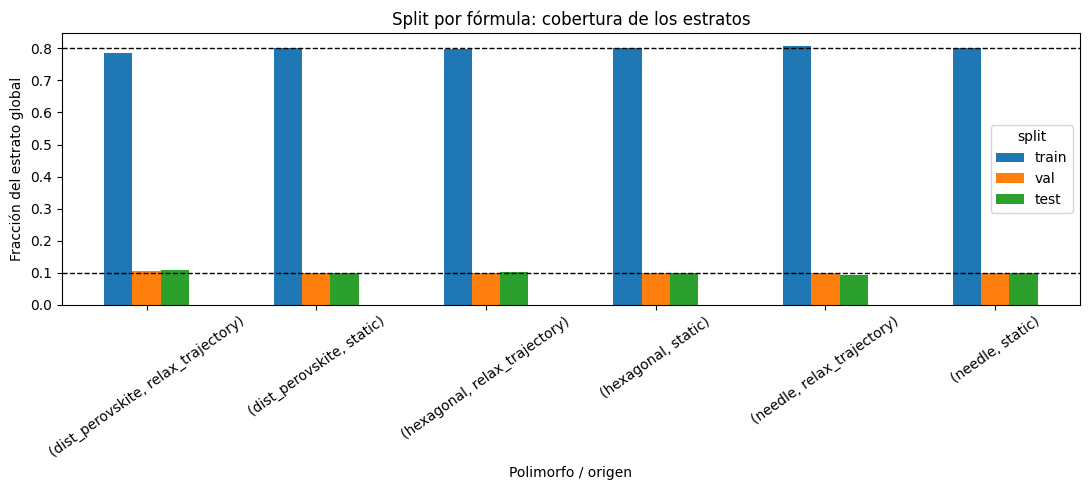

In [5]:
summary_rows = []
stratum_rows = []
for name, fraction in zip(SPLIT_NAMES, SPLIT_FRACTIONS):
    subset = configuration_index[configuration_index["split"] == name]
    summary_rows.append({
        "split": name, "target_fraction": fraction,
        "formulas": subset["formula"].nunique(),
        "formula_fraction": subset["formula"].nunique() / len(formulas),
        "configurations": len(subset),
        "configuration_fraction": len(subset) / len(configuration_index),
        "configuration_deviation_pp": 100 * (len(subset) / len(configuration_index) - fraction),
        "trajectories": subset.loc[subset["data_origin"] == "relax_trajectory", "source_key"].nunique(),
        "static": int(subset["data_origin"].eq("static").sum()),
    })
    for (polymorph, origin), total in composition.items():
        count = int(((subset["polymorph"] == polymorph) & (subset["data_origin"] == origin)).sum())
        stratum_rows.append({
            "split": name, "polymorph": polymorph, "data_origin": origin,
            "global_count": int(total), "configurations": count,
            "target_count": float(fraction * total), "fraction_of_stratum": count / total,
            "deviation_pp": 100 * (count / total - fraction),
        })
split_summary = pd.DataFrame(summary_rows)
stratification_report = pd.DataFrame(stratum_rows)
display(split_summary)
display(stratification_report)
missing_strata = stratification_report.query("configurations == 0")
print("Estratos ausentes por split:", len(missing_strata))
if len(missing_strata):
    display(missing_strata)

plot_table = stratification_report.pivot(
    index=["polymorph", "data_origin"], columns="split", values="fraction_of_stratum"
).reindex(columns=SPLIT_NAMES)
fig, ax = plt.subplots(figsize=(11, 5))
plot_table.plot.bar(ax=ax)
for value in sorted(set(SPLIT_FRACTIONS)):
    ax.axhline(value, color="black", linestyle="--", linewidth=1)
ax.set_ylabel("Fracción del estrato global")
ax.set_xlabel("Polimorfo / origen")
ax.set_title("Split por fórmula: cobertura de los estratos")
ax.tick_params(axis="x", rotation=35)
fig.tight_layout()
plt.show()
plt.close(fig)

## 7. Invariantes: ausencia de leakage y conservación exacta

Antes de exportar se comprueba que cada fórmula, trayectoria e ID pertenece a un único split, que los tamaños por fórmula son los declarados y que la unión de los splits reproduce exactamente la entrada. Cada archivo conserva el orden relativo original.

Los objetos ASE se seleccionan sin modificar sus metadatos ni calculadores. La asignación se guarda en CSV separados; energía, fuerzas, stress, especies, posiciones y celda siguen siendo los de la fuente. La ausencia de leakage comprobada aquí es por composición/fórmula y procedencia; no constituye una auditoría de posibles decisiones globales tomadas en los notebooks anteriores.

In [6]:
assert configuration_index["split"].notna().all()
for column in ("formula", "source_key", "config_id"):
    assert configuration_index.groupby(column)["split"].nunique().eq(1).all(), column
formula_sets = {name: set(formula_assignment.loc[formula_assignment["split"] == name, "formula"])
                for name in SPLIT_NAMES}
for i, name in enumerate(SPLIT_NAMES):
    assert len(formula_sets[name]) == group_counts[i]
    for other in SPLIT_NAMES[i + 1:]:
        assert formula_sets[name].isdisjoint(formula_sets[other])
assert set.union(*formula_sets.values()) == set(formulas)
split_atoms = {
    name: [atoms_all[int(index)] for index in configuration_index.loc[
        configuration_index["split"] == name, "source_index"
    ]]
    for name in SPLIT_NAMES
}
all_assigned_ids = [atoms.info["config_id"] for subset in split_atoms.values() for atoms in subset]
assert len(all_assigned_ids) == len(set(all_assigned_ids)) == len(atoms_all)
assert set(all_assigned_ids) == set(configuration_index["config_id"])
assert sum(len(subset) for subset in split_atoms.values()) == len(atoms_all)
assert sha256_file(SOURCE_EXTXYZ) == source_hash, "La fuente cambió durante la ejecución."
print("Invariantes de grupos, cobertura, unicidad y conservación: OK")

Invariantes de grupos, cobertura, unicidad y conservación: OK


## 8. Exportación y manifiesto de reproducibilidad

Se generan `train.extxyz`, `val.extxyz` y `test.extxyz`, listos para su conversión posterior al formato del entrenador. Este notebook no ejecuta la conversión a LMDB ni entrenamiento.

Artefactos de auditoría:

- `formula_assignment.csv`: asignación canónica de cada fórmula y su número de configuraciones.
- `configuration_index.csv`: ID, procedencia, fórmula original/canónica, orden y split de cada configuración.
- `split_summary.csv`: tamaños y porcentajes reales.
- `stratification_report.csv`: conteos y desviaciones por polimorfo/origen/split.
- `search_history.csv`: puntuación de todos los candidatos.
- `stratification.png`: comparación visual de proporciones.
- `manifest.json`: SHA-256 de fuente y salidas, parámetros, fórmulas seleccionadas y versiones.

Todos los destinos se revisan antes de escribir. Si alguno existe y `OVERWRITE_OUTPUTS=False`, se detiene la exportación. La fuente nunca puede ser un destino. La celda siguiente verifica la lectura de los archivos escritos antes de marcar el manifiesto como verificado.

In [7]:
output_names = [f"{name}.extxyz" for name in SPLIT_NAMES] + [
    "formula_assignment.csv", "configuration_index.csv", "split_summary.csv",
    "stratification_report.csv", "search_history.csv", "stratification.png", "manifest.json",
]
output_paths = [OUTPUT_DIR / name for name in output_names]
assert SOURCE_EXTXYZ.resolve() not in [path.resolve() for path in output_paths]
manifest = {
    "source": str(SOURCE_EXTXYZ), "source_sha256": source_hash,
    "policy": "formula_grouped_stratified_candidate_search",
    "group_key": "ASE reduced composition in Hill notation",
    "strata": ["polymorph", "data_origin"],
    "fractions": dict(zip(SPLIT_NAMES, SPLIT_FRACTIONS.tolist())),
    "fraction_unit": "unique formulas; frame fractions approximate",
    "rounding": "largest remainder; stable train-val-test tie break",
    "seed": SPLIT_SEED, "rng": "numpy.PCG64", "n_candidates": N_CANDIDATES,
    "selected_candidate": int(best_candidate),
    "score": float(search_history.loc[best_candidate, "score"]),
    "objective": "mean((stratum_count/target-1)^2) + mean((total_count/target-1)^2)",
    "formula_splits": {name: sorted(values) for name, values in formula_sets.items()},
    "summary": split_summary.to_dict(orient="records"),
    "versions": {"python": platform.python_version(), "numpy": np.__version__,
                 "pandas": pd.__version__, "ase": ase.__version__},
    "disk_verified": False,
}
if WRITE_OUTPUTS:
    existing = [str(path) for path in output_paths if path.exists()]
    if existing and not OVERWRITE_OUTPUTS:
        raise FileExistsError(f"Salidas existentes; cambie OUTPUT_DIR o habilite OVERWRITE_OUTPUTS: {existing}")
    OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
    for name, subset in split_atoms.items():
        write(OUTPUT_DIR / f"{name}.extxyz", subset, format="extxyz")
    for filename, table in {
        "formula_assignment.csv": formula_assignment,
        "configuration_index.csv": configuration_index,
        "split_summary.csv": split_summary,
        "stratification_report.csv": stratification_report,
        "search_history.csv": search_history,
    }.items():
        table.to_csv(OUTPUT_DIR / filename, index=False)
    fig.savefig(OUTPUT_DIR / "stratification.png", dpi=180, bbox_inches="tight")
    manifest["output_sha256"] = {
        path.name: sha256_file(path) for path in output_paths if path.name != "manifest.json"
    }
    (OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print("Archivos escritos en:", OUTPUT_DIR)
else:
    print("WRITE_OUTPUTS=False: auditoría en memoria; no se exportaron archivos.")

Archivos escritos en: /users/0/cmadridl/projects/dmc_cristelle-madrid-lopez/projects/ABS3-fine-tuning/dev/data/cml/data/configurations_hex_no_meta_split


## 9. Verificación desde disco

Se reabren los tres EXTXYZ y se comparan contra las configuraciones de entrada seleccionadas: IDs y orden exactos; metadatos, especies y periodicidad conservados; posiciones, celda y labels iguales dentro de la precisión de serialización de EXTXYZ (`atol=1e-8`, `rtol=1e-10`). También se reabren las tablas de asignación y se verifican los hashes.

El manifiesto solo recibe `disk_verified=true` cuando todas las comprobaciones pasan. Un fallo deja la exportación sin certificar; revisar la causa antes de utilizar esos archivos para entrenar.

In [8]:
if WRITE_OUTPUTS:
    for name in SPLIT_NAMES:
        restored = read(OUTPUT_DIR / f"{name}.extxyz", index=":", format="extxyz")
        expected = split_atoms[name]
        assert len(restored) == len(expected)
        for actual, original in zip(restored, expected):
            assert actual.info.keys() == original.info.keys()
            for key in original.info:
                np.testing.assert_equal(actual.info[key], original.info[key])
            np.testing.assert_array_equal(actual.numbers, original.numbers)
            np.testing.assert_array_equal(actual.pbc, original.pbc)
            for received, source in (
                (actual.positions, original.positions),
                (actual.cell.array, original.cell.array),
                (actual.get_potential_energy(), original.get_potential_energy()),
                (actual.get_forces(), original.get_forces()),
                (actual.get_stress(voigt=False), original.get_stress(voigt=False)),
            ):
                np.testing.assert_allclose(received, source, atol=1e-8, rtol=1e-10)
    pd.testing.assert_frame_equal(pd.read_csv(OUTPUT_DIR / "formula_assignment.csv"), formula_assignment)
    pd.testing.assert_frame_equal(pd.read_csv(OUTPUT_DIR / "configuration_index.csv"), configuration_index)
    for filename, expected_hash in manifest["output_sha256"].items():
        assert sha256_file(OUTPUT_DIR / filename) == expected_hash
    assert sha256_file(SOURCE_EXTXYZ) == source_hash
    manifest["disk_verified"] = True
    (OUTPUT_DIR / "manifest.json").write_text(json.dumps(manifest, indent=2) + "\n")
    print("Verificación de archivos, metadatos, labels, asignaciones y hashes: OK")
    display(split_summary)

Verificación de archivos, metadatos, labels, asignaciones y hashes: OK


,split,target_fraction,formulas,formula_fraction,configurations,configuration_fraction,configuration_deviation_pp,trajectories,static
0,train,0.8,64,0.8,6860,0.798975,-0.102492,192,192
1,val,0.1,8,0.1,889,0.103541,0.354065,24,24
2,test,0.1,8,0.1,837,0.097484,-0.251572,24,24


## Resultado e interpretación para los experimentos

Los archivos `train.extxyz`, `val.extxyz` y `test.extxyz` contienen una partición exhaustiva y sin solapamiento por fórmula del dataset de entrada. Con 80 fórmulas, los grupos son 64/8/8; los porcentajes de frames se consultan en `split_summary.csv` y la fidelidad de la estratificación en `stratification_report.csv`.

Usar train para ajustar el modelo, val para seleccionar hiperparámetros y checkpoints, y test para la evaluación final. Las transformaciones que aprendan parámetros en etapas posteriores deben ajustarse con train. Mantener fija `formula_assignment.csv` para comparar experimentos; no volver a buscar un split basándose en resultados del modelo.

La agrupación garantiza separación de composiciones entre particiones. La estratificación equilibra los estratos declarados de forma aproximada: no garantiza equilibrio de elementos químicos, energías, fuerzas ni propiedades no incluidas en el objetivo.